In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:

df = pd.read_excel(
    "/content/PSDS_WDI_working.xlsx",
    sheet_name="work")

df.head()

,country,year,Exports of goods and services (annual % growth),REER,GDP growth (annual %),"Inflation, consumer prices (annual %)","Foreign direct investment, net inflows (% of GDP)",Trade (% of GDP)
0,Pakistan,2001,13.349373,98.157597,3.651350,3.148261,0.389107,23.577207
1,Pakistan,2002,13.128090,101.706531,2.594817,3.290345,0.843517,23.129016
2,Pakistan,2003,25.847213,98.922873,5.401311,2.914135,0.475208,24.650159
3,Pakistan,2004,-1.353850,98.079716,7.831256,7.444625,0.845586,24.808335
4,Pakistan,2005,17.589346,101.010993,7.276574,9.063327,1.515751,29.878494


tells us the no. of rows and columns

In [9]:
df.shape

(200, 8)

tells us the no. of columns present in the dataset

In [10]:
df.columns

Index(['country', 'year', 'Exports of goods and services (annual % growth)',
       'REER', 'GDP growth (annual %)',
       'Inflation, consumer prices (annual %)',
       'Foreign direct investment, net inflows (% of GDP)',
       'Trade (% of GDP)'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   country                                            200 non-null    object 
 1   year                                               200 non-null    int64  
 2   Exports of goods and services (annual % growth)    200 non-null    float64
 3   REER                                               200 non-null    float64
 4   GDP growth (annual %)                              200 non-null    float64
 5   Inflation, consumer prices (annual %)              200 non-null    float64
 6   Foreign direct investment, net inflows (% of GDP)  200 non-null    float64
 7   Trade (% of GDP)                                   200 non-null    float64
dtypes: float64(6), int64(1), object(1)
memory usage: 12.6+ KB


Descriptive statistics

In [12]:
df.describe().round(2)

,year,Exports of goods and services (annual % growth),REER,GDP growth (annual %),"Inflation, consumer prices (annual %)","Foreign direct investment, net inflows (% of GDP)",Trade (% of GDP)
count,200.00,200.00,200.00,200.00,200.00,200.00,200.00
mean,2013.00,5.06,90.88,3.49,6.62,2.58,54.23
std,7.23,8.14,15.25,3.14,6.11,1.78,20.92
min,2001.00,-22.46,53.83,-9.52,-0.69,-0.51,22.11
25%,2007.00,1.08,78.12,2.04,3.27,1.32,34.95
50%,2013.00,4.84,95.62,3.65,5.02,2.31,55.57
75%,2019.00,9.23,102.36,5.43,7.72,3.25,69.52
max,2025.00,53.84,123.07,14.05,41.51,9.68,110.05


Interpretations:
1. Mean = 5.06%
Across the 200 country-year observations, average annual export growth was 5.06%.
Notice that we're not saying every country's exports grew by 5.06%. This is the overall average across the entire dataset.
2. Standard deviation = 8.14 percentage points
This tells us export growth varied substantially across observations.
Why is this important? Because your model is trying to predict export contractions, and export growth clearly fluctuates.
3. Minimum = -22.46%
At least one country-year experienced a considerable export contraction.
4. Maximum = 53.84%
At least one observation experienced exceptionally strong export growth.
These extreme observations should be investigated during EDA, but they aren't automatically errors.
5. Median = 4.84%
Half of the observations have export growth at or below 4.84%, and half have growth at or above 4.84%.
The mean and median are relatively close, but we need a histogram before drawing stronger conclusions about the shape of the distribution.

Average GDP growth is positive at 3.49%, but the minimum of -9.52% shows that some country-years experienced substantial economic contractions.
For this research, this raises a useful question:
Are countries experiencing weak GDP growth more likely to experience export contractions in the following year?

The inflation maximum of 41.51% is considerably higher than the median of 5.02%.
This suggests that your dataset includes periods of unusually high inflation.
Also, the mean exceeds the median, which may indicate a right-skewed distribution.
We'll investigate that with a histogram.

REER is an index, not a percentage growth rate.
the proposal focuses on annual changes in REER, so these statistics describe the index levels but don't yet tell us the distribution of currency appreciation and depreciation.
Later, we'll calculate annual REER percentage changes separately for each country.

On average, FDI net inflows represented 2.58% of GDP across the observations.
The negative minimum is possible because net investment flows can be negative.
So we should not automatically label it a data error.

In [13]:

# Find the observation with the lowest export growth
df.loc[
    df["Exports of goods and services (annual % growth)"].idxmin()
]


,119
country,Colombia
year,2020
Exports of goods and services (annual % growth),-22.459265
REER,68.035535
GDP growth (annual %),-7.185914
"Inflation, consumer prices (annual %)",2.526635
"Foreign direct investment, net inflows (% of GDP)",2.758894
Trade (% of GDP),34.055571


In [14]:

# Find the observation with the lowest export growth
df.loc[
    df["Exports of goods and services (annual % growth)"].idxmax()
]


,185
country,Ghana
year,2011
Exports of goods and services (annual % growth),53.842083
REER,93.666642
GDP growth (annual %),14.047124
"Inflation, consumer prices (annual %)",8.728459
"Foreign direct investment, net inflows (% of GDP)",8.25588
Trade (% of GDP),86.295454


What do these results tell us?
Colombia, 2020: Export growth was -22.46%, while GDP growth was -7.19%. This means both exports and overall economic output contracted in that year.
The COVID-19 pandemic is a plausible contextual explanation, but we would need additional evidence to establish the factors behind Colombia's decline.
Ghana, 2011: Export growth reached 53.84%, while GDP growth was 14.05%. This was an unusually strong expansion relative to the average export growth in your sample.
Notice something interesting: the highest export-growth observation also has very high GDP growth, while the lowest export-growth observation has negative GDP growth.
Does that mean GDP growth predicts export performance?
Not necessarily. These are only two observations, and both figures describe the same year. Your project aims to predict next-year export contractions. We will need to examine the full dataset and align predictors with future outcomes before drawing conclusions.

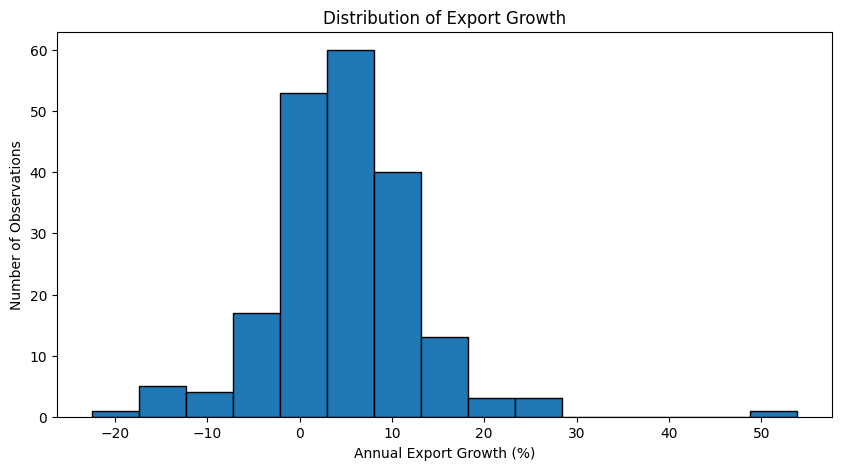

In [15]:

plt.figure(figsize=(10, 5))

plt.hist(
    df["Exports of goods and services (annual % growth)"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Export Growth")
plt.xlabel("Annual Export Growth (%)")
plt.ylabel("Number of Observations")

plt.show()


The histogram illustrates the distribution of annual export growth across 200 country-year observations. Most observations are concentrated around modest positive growth rates, while a smaller number show negative export growth. The distribution contains extreme observations on both sides, including a particularly high positive value. This indicates substantial variation in export performance across countries and years.

This is descriptive, not causal, which is appropriate for your EDA.

now i am going to set export contrsctions threshold

Export Growth<0%

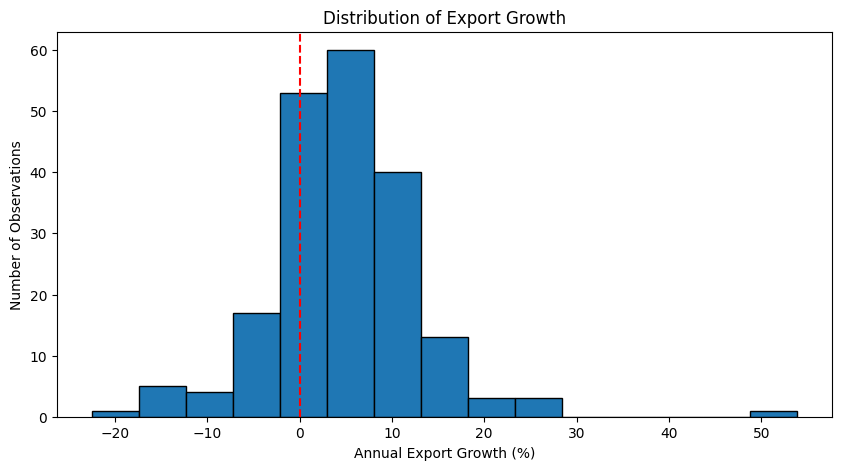

In [16]:

plt.figure(figsize=(10, 5))

plt.hist(
    df["Exports of goods and services (annual % growth)"],
    bins=15,
    edgecolor="black"
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Distribution of Export Growth")
plt.xlabel("Annual Export Growth (%)")
plt.ylabel("Number of Observations")

plt.show()


In [17]:

# Select the export growth column
exports = df["Exports of goods and services (annual % growth)"]

# Count negative export growth observations
contractions = (exports < 0).sum()

# Count zero or positive export growth observations
no_contractions = (exports >= 0).sum()

print("Export contractions:", contractions)
print("No contractions:", no_contractions)


Export contractions: 39
No contractions: 161


In [1]:

# Create categories and their counts
categories = ["Contraction", "No Contraction"]
counts = [contractions, no_contractions]

# Create the bar chart
plt.figure(figsize=(7, 5))

plt.bar(categories, counts)

plt.title("Frequency of Export Contractions")
plt.xlabel("Export Growth Category")
plt.ylabel("Number of Observations")

plt.show()


NameError: name 'contractions' is not defined